# ACIT4620 — HAM10000 Skin Lesion Dataset: Phase 1 Full Audit

**Project:** Data-Centric Pretrained EfficientNet-B0 + Mamdani Fuzzy Inference for Seven-Class Skin Lesion Classification  
**Goal:** Thorough, reproducible exploratory data analysis (EDA) and leakage-safe dataset preparation **before model training**.  
**Source:** [Kaggle HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000). Original dataset: [Tschandl et al. (2018)](https://doi.org/10.7910/DVN/DBW86T).

### How to run this notebook in Kaggle

1. Open the dataset's Kaggle page and click **New Notebook/Create notebook**, or create a notebook and **Add Input** → `Skin Cancer MNIST: HAM10000`.
2. Set **Accelerator = None** (GPU not required for audit), and rename this notebook `ACIT4620_HAM10000_Phase1_Dataset_Inspection`.
3. **Run cells from top to bottom**, reviewing every table and figure. Nothing in `/kaggle/input/` will be modified.
4. Output tables/plots/reports are written to `/kaggle/working/ham10000_audit/`.
5. After completing the audit, select **Save Version → Save & Run All** for reproducible outputs. Inspect the saved version's **Output** files.

**Important:** These seven labels are *skin lesion diagnoses*, not seven cancer types. No predictions or clinical risk decisions are made in this notebook.

### Audit checklist
- [ ] Dataset files and image-to-metadata mapping verified
- [ ] Missing/unknown data, invalid categories, duplicate IDs checked
- [ ] Class imbalance measured; minority/majority classes identified
- [ ] Age, sex, body site, and diagnostic confirmation method profiled
- [ ] Lesion IDs and multiple images per lesion understood
- [ ] Representative images inspected across all seven classes
- [ ] Dimensions, channels, corruption and suspicious pixel values audited
- [ ] Exact image duplicates evaluated (optional but recommended)
- [ ] Lesion-disjoint train/validation/test splits created and checked
- [ ] Figures, summaries and CSV manifests exported for the report

## 1. Reproducibility, libraries, paths, and configuration

In [1]:
from pathlib import Path
from collections import defaultdict
from pprint import pprint
import hashlib
import json
import os
import platform
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display
from tqdm.auto import tqdm
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

INPUT = Path('/kaggle/input')
OUTPUT = Path('/kaggle/working/ham10000_audit')
OUTPUT.mkdir(parents=True, exist_ok=True)

DX_NAMES = {
    'akiec': 'Actinic keratoses / intraepithelial carcinoma',
    'bcc': 'Basal cell carcinoma',
    'bkl': 'Benign keratosis-like lesions',
    'df': 'Dermatofibroma',
    'mel': 'Melanoma',
    'nv': 'Melanocytic nevi',
    'vasc': 'Vascular lesions'
}
DX_ORDER = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']

# Start with a representative sample. For a complete audit, set this to True.
RUN_FULL_IMAGE_AUDIT = True
SAMPLED_IMAGE_COUNT = 600
# Recommended when you have time: scans image file contents (~3 GB in this dataset).
RUN_EXACT_HASH_AUDIT = True

print('Python:', sys.version.split()[0])
print('Pandas:', pd.__version__, '| NumPy:', np.__version__, '| scikit-learn:', sklearn.__version__)
print('Platform:', platform.platform())
print('Inputs available:', INPUT.exists())
print('Output directory:', OUTPUT)

Python: 3.13.15
Pandas: 2.3.3 | NumPy: 2.1.3 | scikit-learn: 1.6.1
Platform: Linux-6.18.48+-x86_64-with-glibc2.39
Inputs available: True
Output directory: /kaggle/working/ham10000_audit


## 2. Automatically locate the correct dataset and list all files

The original full-size `.jpg` files in two image folders are used for deep learning. The `hmnist_8_8` and `hmnist_28_28` CSVs are reduced-resolution alternatives, **not** replacements for the original images.

In [2]:
metadata_candidates = sorted(INPUT.rglob('HAM10000_metadata.csv'))
if not metadata_candidates:
    raise FileNotFoundError('HAM10000_metadata.csv not found. Kaggle notebook → Add Input → Skin Cancer MNIST: HAM10000.')
if len(metadata_candidates) > 1:
    print('Warning: multiple HAM10000 metadata files found. Using first; check other attached sources.')
    print('\n'.join(map(str, metadata_candidates)))
META_PATH = metadata_candidates[0]
DATA_DIR = META_PATH.parent
print('DATA_DIR:', DATA_DIR)

inventory = []
for f in sorted(DATA_DIR.rglob('*')):
    if f.is_file():
        inventory.append({
            'relative_path': str(f.relative_to(DATA_DIR)),
            'extension': f.suffix.lower(),
            'size_mb': round(f.stat().st_size / (1024**2), 3)
        })
file_inventory = pd.DataFrame(inventory)
print('Total files:', len(file_inventory))
print('Total size (GiB):', round(file_inventory['size_mb'].sum() / 1024, 2))
print('\nFile extensions:')
print(file_inventory['extension'].value_counts().to_string())
print('\nTop-level entries:')
print([x.name for x in sorted(DATA_DIR.iterdir())])
file_inventory.to_csv(OUTPUT / 'file_inventory.csv', index=False)
display(file_inventory[~file_inventory['extension'].isin(['.jpg', '.jpeg', '.png'])].head(25))

DATA_DIR: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
Total files: 20035
Total size (GiB): 5.28

File extensions:
extension
.jpg    20030
.csv        5

Top-level entries:
['HAM10000_images_part_1', 'HAM10000_images_part_2', 'HAM10000_metadata.csv', 'ham10000_images_part_1', 'ham10000_images_part_2', 'hmnist_28_28_L.csv', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_L.csv', 'hmnist_8_8_RGB.csv']


,relative_path,extension,size_mb
10015,HAM10000_metadata.csv,.csv,0.537
20031,hmnist_28_28_L.csv,.csv,29.381
20032,hmnist_28_28_RGB.csv,.csv,87.567
20033,hmnist_8_8_L.csv,.csv,2.420
20034,hmnist_8_8_RGB.csv,.csv,7.176


## 3. Read the primary metadata, its schema and a few records

Expected columns usually include `lesion_id`, `image_id`, `dx`, `dx_type`, `age`, `sex`, `localization`. `dx` is the target; `dx_type` documents how the diagnosis was confirmed.

In [3]:
df = pd.read_csv(META_PATH)
required = ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
missing_columns = sorted(set(required) - set(df.columns))
if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}; review the dataset version.')

print('Metadata shape (rows, columns):', df.shape)
print('\nColumns:', list(df.columns))
print('\nData types:')
print(df.dtypes.to_string())
print('\nSample records:')
display(df.head(10))
print('\nDescriptive statistics:')
display(df.describe(include='all').T)

Metadata shape (rows, columns): (10015, 7)

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Data types:
lesion_id        object
image_id         object
dx               object
dx_type          object
age             float64
sex              object
localization     object

Sample records:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear
5,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear
6,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face
7,HAM_0002761,ISIC_0029068,bkl,histo,60.0,male,face
8,HAM_0005132,ISIC_0025837,bkl,histo,70.0,female,back
9,HAM_0005132,ISIC_0025209,bkl,histo,70.0,female,back



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
lesion_id,10015,7470,HAM_0000835,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_id,10015,10015,ISIC_0032258,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dx,10015,7,nv,6705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dx_type,10015,4,histo,5340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,9958.0,NaN,NaN,NaN,51.863828,16.968614,0.0,40.0,50.0,65.0,85.0
sex,10015,3,male,5406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
localization,10015,15,back,2192,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data dictionary and quality-control report

**Distinct concepts:** `image_id` identifies a photograph; `lesion_id` identifies a physical lesion (potentially photographed multiple times). The dataset does **not** provide a dependable patient ID field for patient-disjoint splitting. A lesion-disjoint split is important but should not be mislabelled as patient-disjoint.

In [4]:
field_descriptions = pd.DataFrame([
    ('lesion_id', 'Group key for repeated images of the same skin lesion', 'Group splitting ONLY'),
    ('image_id', 'Unique image identifier', 'Lookup ONLY'),
    ('dx', 'Seven-class diagnosis label', 'Prediction target'),
    ('dx_type', 'Confirmation method: histo, follow_up, consensus, confocal', 'Data-quality analysis ONLY'),
    ('age', 'Reported age, may be missing', 'Optional input, after careful handling'),
    ('sex', 'Reported sex or unknown', 'Optional input, after careful handling'),
    ('localization', 'Anatomical location on body', 'Optional input, after careful handling')
], columns=['column', 'meaning', 'proposed_use'])
display(field_descriptions)

qc_rows = []
for col in df.columns:
    s = df[col]
    lower = s.astype('string').str.strip().str.lower()
    qc_rows.append({
        'column': col,
        'dtype': str(s.dtype),
        'null_count': int(s.isna().sum()),
        'null_pct': round(100 * s.isna().mean(), 2),
        'unknown_text_count': int(lower.isin(['unknown', 'unk', 'not known', '']).sum()),
        'distinct_non_null': int(s.nunique(dropna=True))
    })
missing_report = pd.DataFrame(qc_rows)
display(missing_report)
missing_report.to_csv(OUTPUT / 'metadata_missingness.csv', index=False)

print('Exact duplicate metadata rows:', int(df.duplicated().sum()))
print('Duplicate image IDs:', int(df['image_id'].duplicated().sum()))
print('Missing lesion IDs:', int(df['lesion_id'].isna().sum()))
print('Unknown dx codes:', sorted(set(df['dx'].dropna()) - set(DX_NAMES)))
print('Negative ages:', int((pd.to_numeric(df['age'], errors='coerce') < 0).sum()))
print('Ages > 110:', int((pd.to_numeric(df['age'], errors='coerce') > 110).sum()))
assert not df['image_id'].duplicated().any(), 'Duplicate image IDs; inspect before continuing.'
assert df['lesion_id'].notna().all(), 'Missing lesion IDs; cannot make valid group splits.'
assert df['dx'].isin(DX_NAMES).all(), 'Unknown/missing diagnosis codes; inspect first.'

,column,meaning,proposed_use
0,lesion_id,Group key for repeated images of the same skin...,Group splitting ONLY
1,image_id,Unique image identifier,Lookup ONLY
2,dx,Seven-class diagnosis label,Prediction target
3,dx_type,"Confirmation method: histo, follow_up, consens...",Data-quality analysis ONLY
4,age,"Reported age, may be missing","Optional input, after careful handling"
5,sex,Reported sex or unknown,"Optional input, after careful handling"
6,localization,Anatomical location on body,"Optional input, after careful handling"


,column,dtype,null_count,null_pct,unknown_text_count,distinct_non_null
0,lesion_id,object,0,0.00,0,7470
1,image_id,object,0,0.00,0,10015
2,dx,object,0,0.00,0,7
3,dx_type,object,0,0.00,0,4
4,age,float64,57,0.57,0,18
5,sex,object,0,0.00,57,3
6,localization,object,0,0.00,234,15


Exact duplicate metadata rows: 0
Duplicate image IDs: 0
Missing lesion IDs: 0
Unknown dx codes: []
Negative ages: 0
Ages > 110: 0


## 5. Reconcile the image files with the metadata (duplicate-folder-aware)

Some Kaggle releases include **two complete copies** of the same 10,015 image files in different folders (20,030 file paths, but 10,015 `image_id` values). This is **not** evidence of 20,030 distinct images.

This version detects duplicate filenames, verifies repeated copies with file size and SHA-256, and selects **one canonical file per image ID only when the contents match exactly**. If any repeated filename maps to different bytes, the cell stops, writes `image_copy_audit.csv`, and asks for manual review. Do **not** remove images or silently pick the first path when the contents differ.

SHA-256 verification can take a few minutes; keep the Kaggle session active.


### Fast-mode verification (reuses previous full SHA-256 copy check)

In the earlier Kaggle interactive audit, **all 10,015 duplicate-folder image pairs were verified byte-identical using SHA-256**. This optimized notebook intentionally skips repeating that slow pairwise hashing. Instead, it confirms every copy filename exists and file size matches, then uses only the uppercase canonical folders. This is valid for the **same unchanged Kaggle dataset version**; **file size equality alone is not proof of byte equality**. Use the original full-verification notebook again if the input dataset changes. The optional Section 13 independent cross-image SHA-256 audit should still be run before final modeling.


In [5]:
# FAST CANONICAL IMAGE RECONCILIATION
# The previous run verified all 10,015 repeated IDs had SHA-256-identical
# copies in the upper/lower-case folders. This cell does NOT repeat that
# 5.28 GiB read. It checks that the same directory structure is present,
# ensures matching filenames + sizes across copies, then uses one canonical
# file per ID. Full independent cross-image SHA-256 audit is still available
# in Section 13. Re-enable full duplicate-copy verification with the original
# notebook if the dataset version/source changes.

CANONICAL_DIRS = [
    DATA_DIR / 'HAM10000_images_part_1',
    DATA_DIR / 'HAM10000_images_part_2',
]
COPY_DIRS = [
    DATA_DIR / 'ham10000_images_part_1',
    DATA_DIR / 'ham10000_images_part_2',
]
for folder in CANONICAL_DIRS + COPY_DIRS:
    assert folder.is_dir(), f'Expected folder missing: {folder}'

canonical_paths = sorted(
    p for folder in CANONICAL_DIRS for p in folder.glob('*.jpg')
)
image_lookup = {}
for path in canonical_paths:
    assert path.stem not in image_lookup, f'ID collision in canonical files: {path.stem}'
    image_lookup[path.stem] = str(path)

assert len(image_lookup) == 10015, f'Expected 10,015 canonical images, found {len(image_lookup)}'
assert df['image_id'].is_unique, 'Duplicate image IDs in metadata.'

# Check expected secondary copies are present and have equal byte lengths.
# Equality of file lengths alone does NOT prove byte-identical content.
copy_report = []
for main_dir, dup_dir in zip(CANONICAL_DIRS, COPY_DIRS):
    main_files = {p.name: p for p in main_dir.glob('*.jpg')}
    dup_files = {p.name: p for p in dup_dir.glob('*.jpg')}
    assert set(main_files) == set(dup_files), (
        f'File lists differ between {main_dir.name} and {dup_dir.name}. '
        'Re-run the full duplicate-copy audit.'
    )
    for name, main_path in main_files.items():
        duplicate_path = dup_files[name]
        size1 = main_path.stat().st_size
        size2 = duplicate_path.stat().st_size
        assert size1 == size2, (
            f'Different byte sizes for {name}. Re-run full SHA-256 copy audit.'
        )
        copy_report.append({
            'image_id': main_path.stem,
            'canonical_path': str(main_path.relative_to(DATA_DIR)),
            'duplicate_path': str(duplicate_path.relative_to(DATA_DIR)),
            'bytes_each': size1,
            'copy_contents_rehashed_this_run': False,
            'note': 'Equal sizes; SHA-256 pair equality confirmed in previous run only',
        })

pd.DataFrame(copy_report).to_csv(
    OUTPUT / 'image_copy_inventory_fast.csv', index=False
)
image_files = [Path(image_lookup[image_id]) for image_id in sorted(image_lookup)]
df['image_path'] = df['image_id'].map(image_lookup)
df['image_relpath'] = df['image_path'].map(
    lambda x: str(Path(x).relative_to(DATA_DIR)) if isinstance(x, str) else None
)
missing_image_rows = df[df['image_path'].isna()].copy()
orphan_stems = set(image_lookup) - set(df['image_id'])
missing_image_rows.to_csv(OUTPUT / 'missing_images.csv', index=False)
pd.DataFrame({'orphan_image_stem': sorted(orphan_stems)}).to_csv(
    OUTPUT / 'orphan_images.csv', index=False
)
assert missing_image_rows.empty, 'Metadata images are missing.'
assert not orphan_stems, 'Images are absent from metadata.'
assert len(image_files) == len(df), 'Manifest-image count mismatch.'

print('Canonical image files:', len(image_files))
print('Matching duplicate filenames and file sizes:', len(copy_report))
print('Missing metadata images:', len(missing_image_rows))
print('Images without metadata:', len(orphan_stems))
print('NOTE: Pairwise SHA-256 recheck skipped based on previous verified run.')
print('PASS: canonical image paths and metadata reconciliation.')


Canonical image files: 10015
Matching duplicate filenames and file sizes: 10015
Missing metadata images: 0
Images without metadata: 0
NOTE: Pairwise SHA-256 recheck skipped based on previous verified run.
PASS: canonical image paths and metadata reconciliation.


## 6. Class distribution and majority-class baseline

We expect seven diagnostic groups and substantial imbalance. Compute **image count and percentage** per category rather than relying only on the known published distribution.

,dx,diagnosis,images,percent
0,nv,Melanocytic nevi,6705,66.95
1,mel,Melanoma,1113,11.11
2,bkl,Benign keratosis-like lesions,1099,10.97
3,bcc,Basal cell carcinoma,514,5.13
4,akiec,Actinic keratoses / intraepithelial carcinoma,327,3.27
5,vasc,Vascular lesions,142,1.42
6,df,Dermatofibroma,115,1.15


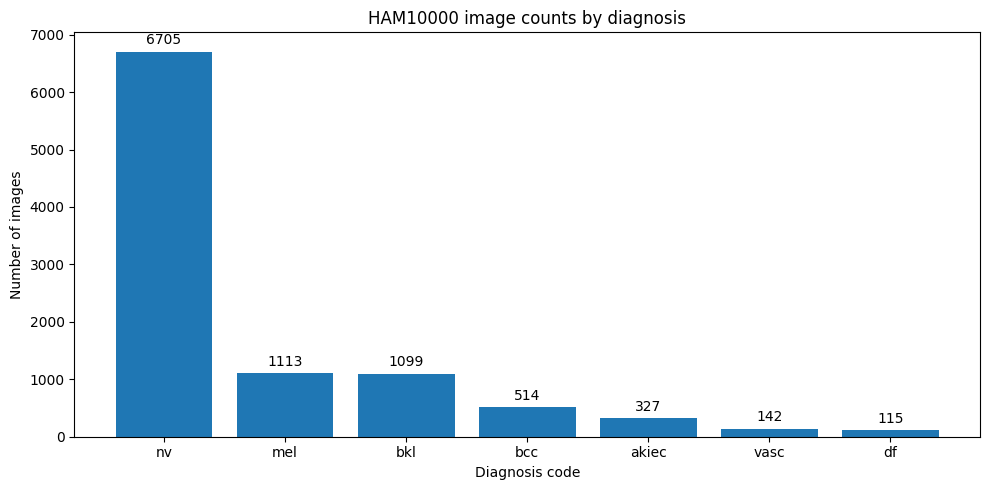

Majority-class-only accuracy: 66.95% (misleading metric for imbalanced multiclass data)
Majority-to-minority ratio: 58.3 : 1


In [6]:
class_counts = df['dx'].value_counts().reindex(DX_ORDER, fill_value=0)
class_table = pd.DataFrame({
    'dx': DX_ORDER,
    'diagnosis': [DX_NAMES[x] for x in DX_ORDER],
    'images': [int(class_counts[x]) for x in DX_ORDER],
    'percent': [round(100 * class_counts[x] / len(df), 2) for x in DX_ORDER]
})
display(class_table)
class_table.to_csv(OUTPUT / 'class_distribution.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(class_table['dx'], class_table['images'])
ax.bar_label(bars, padding=3)
ax.set(title='HAM10000 image counts by diagnosis', xlabel='Diagnosis code', ylabel='Number of images')
plt.tight_layout()
fig.savefig(OUTPUT / '01_class_distribution.png', dpi=180)
plt.show()

largest = int(class_counts.max())
smallest = int(class_counts[class_counts > 0].min())
print('Majority-class-only accuracy:', f'{largest/len(df):.2%}', '(misleading metric for imbalanced multiclass data)')
print('Majority-to-minority ratio:', round(largest / smallest, 1), ': 1')

## 7. Count distinct lesions and repeated photographs

This is a **critical** check for avoiding the same lesion in both training and testing. Also check whether one lesion ID is assigned conflicting diagnoses.

Unique images: 10015
Unique lesion IDs: 7470
Lesions with multiple images: 1956
Images belonging to multi-image lesions: 4501
Max images of one lesion: 6
Lesions with conflicting labels: 0


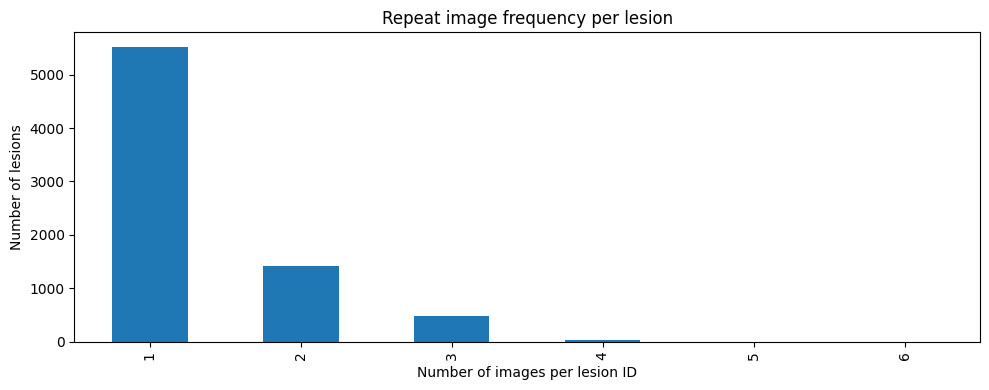

In [7]:
images_per_lesion = df.groupby('lesion_id')['image_id'].nunique()
labels_per_lesion = df.groupby('lesion_id')['dx'].nunique()
conflicting_lesions = labels_per_lesion[labels_per_lesion > 1]
print('Unique images:', df['image_id'].nunique())
print('Unique lesion IDs:', df['lesion_id'].nunique())
print('Lesions with multiple images:', int((images_per_lesion > 1).sum()))
print('Images belonging to multi-image lesions:', int(images_per_lesion[images_per_lesion > 1].sum()))
print('Max images of one lesion:', int(images_per_lesion.max()))
print('Lesions with conflicting labels:', len(conflicting_lesions))
if not conflicting_lesions.empty:
    display(df[df['lesion_id'].isin(conflicting_lesions.index)].sort_values('lesion_id').head(20))

fig, ax = plt.subplots(figsize=(10, 4))
images_per_lesion.value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set(xlabel='Number of images per lesion ID', ylabel='Number of lesions', title='Repeat image frequency per lesion')
plt.tight_layout()
fig.savefig(OUTPUT / '02_images_per_lesion.png', dpi=180)
plt.show()

images_per_lesion.rename('image_count').reset_index().to_csv(OUTPUT / 'images_per_lesion.csv', index=False)
assert conflicting_lesions.empty, 'One or more lesions have conflicting diagnosis labels. Investigate before splitting.'

## 8. Analyze diagnostic label verification (`dx_type`)

This column describes the **reference-standard verification method** (e.g. histopathology or expert consensus). Its distribution may vary across classes. **Never feed `dx_type` into a model as a predictor:** it reflects diagnosis confirmation information that would not normally be available before prediction.

Confirmation methods:


,dx_type,images
0,histo,5340
1,follow_up,3704
2,consensus,902
3,confocal,69


dx_type,confocal,consensus,follow_up,histo
dx,,,,
nv,0,503,3704,2498
mel,0,0,0,1113
bkl,69,264,0,766
bcc,0,0,0,514
akiec,0,0,0,327
vasc,0,75,0,67
df,0,60,0,55


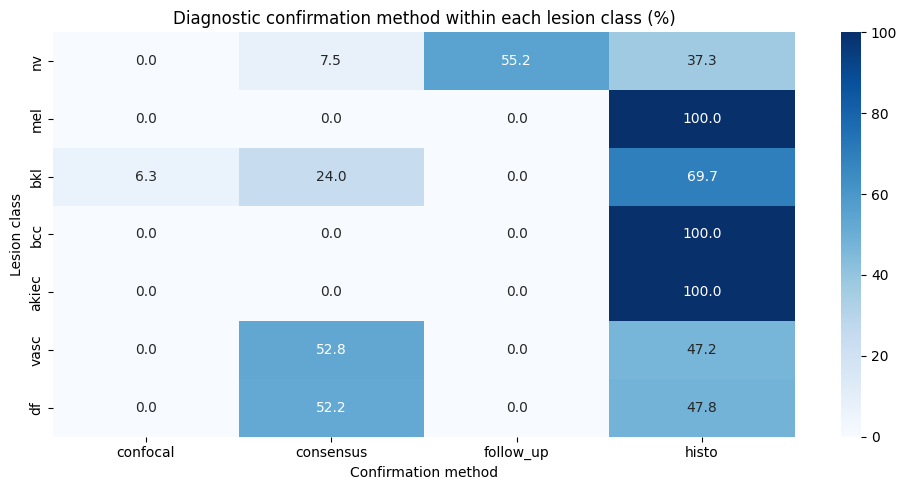

In [8]:
print('Confirmation methods:')
display(df['dx_type'].value_counts(dropna=False).rename_axis('dx_type').reset_index(name='images'))
confirmation_table = pd.crosstab(df['dx'], df['dx_type']).reindex(DX_ORDER, fill_value=0)
display(confirmation_table)
confirmation_table.to_csv(OUTPUT / 'diagnosis_confirmation_by_class.csv')

row_pct = confirmation_table.div(confirmation_table.sum(axis=1).replace(0, np.nan), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(row_pct, annot=True, fmt='.1f', cmap='Blues', ax=ax)
ax.set(title='Diagnostic confirmation method within each lesion class (%)', xlabel='Confirmation method', ylabel='Lesion class')
plt.tight_layout()
fig.savefig(OUTPUT / '03_confirmation_method_heatmap.png', dpi=180)
plt.show()

## 9. Demographic and anatomical metadata exploration

Inspect age, sex and lesion location by diagnosis. Treat unknown and missing values separately. These data are **descriptive**, not proof of population-wide incidence; HAM10000 is a curated dataset with selection bias.

Age missing: 57
Age range: 0.0 to 85.0
Age mean/median: 51.9 / 50.0

Sex counts:


sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64


Anatomical site counts:


localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64

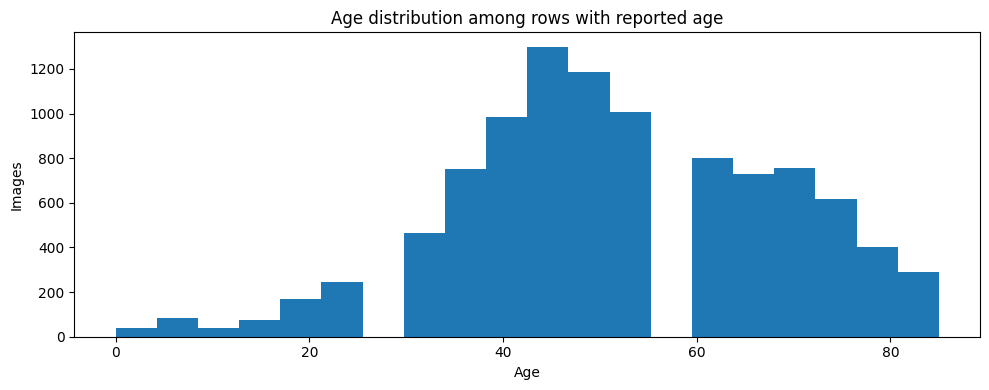

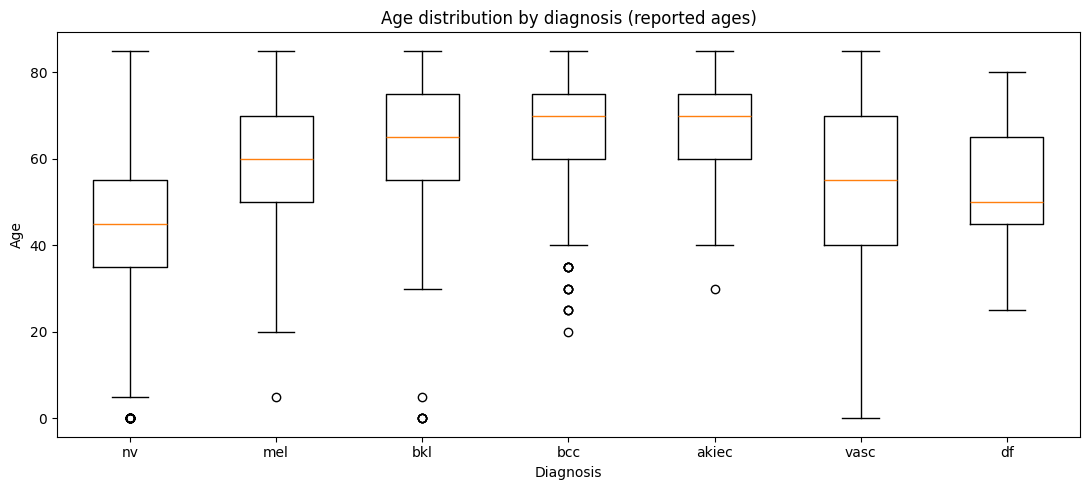

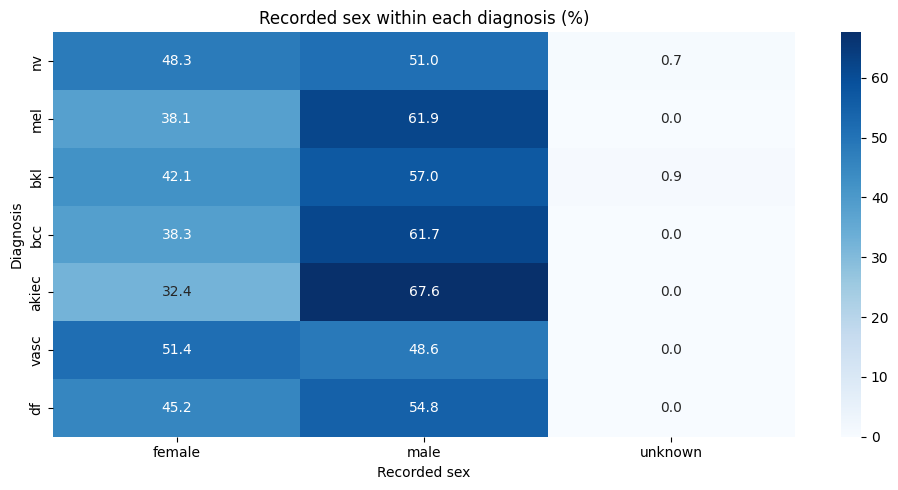

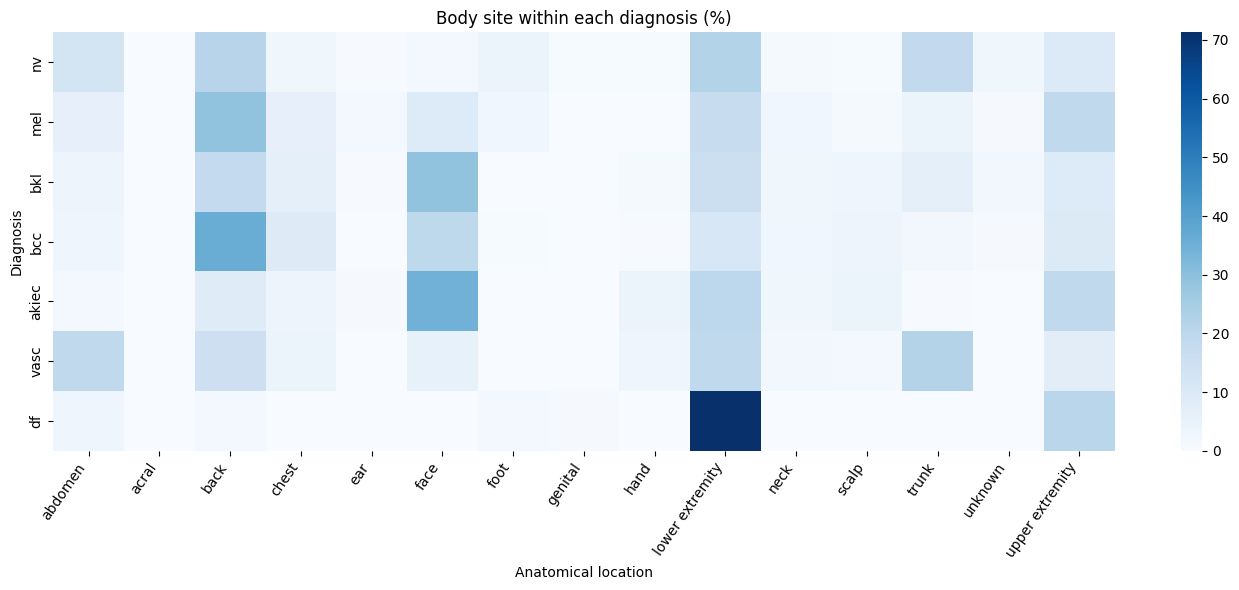

Note: Skin tone / Fitzpatrick type is not a reliable structured metadata column in this release.


In [9]:
df['age_num'] = pd.to_numeric(df['age'], errors='coerce')
print('Age missing:', int(df['age_num'].isna().sum()))
print('Age range:', df['age_num'].min(), 'to', df['age_num'].max())
print('Age mean/median:', round(df['age_num'].mean(), 1), '/', df['age_num'].median())
print('\nSex counts:')
display(df['sex'].value_counts(dropna=False))
print('\nAnatomical site counts:')
display(df['localization'].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df['age_num'].dropna().to_numpy(), bins=20)
ax.set(title='Age distribution among rows with reported age', xlabel='Age', ylabel='Images')
plt.tight_layout()
fig.savefig(OUTPUT / '04_age_distribution.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([df.loc[df['dx'] == dx, 'age_num'].dropna().to_numpy() for dx in DX_ORDER],
           tick_labels=DX_ORDER)
ax.set(title='Age distribution by diagnosis (reported ages)', xlabel='Diagnosis', ylabel='Age')
plt.tight_layout()
fig.savefig(OUTPUT / '05_age_by_class.png', dpi=180)
plt.show()

sex_table = pd.crosstab(df['dx'], df['sex'], dropna=False).reindex(DX_ORDER, fill_value=0)
site_table = pd.crosstab(df['dx'], df['localization'], dropna=False).reindex(DX_ORDER, fill_value=0)
sex_table.to_csv(OUTPUT / 'sex_by_class.csv')
site_table.to_csv(OUTPUT / 'localization_by_class.csv')

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(sex_table.div(sex_table.sum(axis=1), axis=0)*100, annot=True, fmt='.1f', cmap='Blues', ax=ax)
ax.set(title='Recorded sex within each diagnosis (%)', xlabel='Recorded sex', ylabel='Diagnosis')
plt.tight_layout()
fig.savefig(OUTPUT / '06_sex_by_class.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
site_pct = site_table.div(site_table.sum(axis=1), axis=0) * 100
sns.heatmap(site_pct, cmap='Blues', ax=ax)
ax.set(title='Body site within each diagnosis (%)', xlabel='Anatomical location', ylabel='Diagnosis')
plt.xticks(rotation=55, ha='right')
plt.tight_layout()
fig.savefig(OUTPUT / '07_body_site_by_class.png', dpi=180)
plt.show()

print('Note: Skin tone / Fitzpatrick type is not a reliable structured metadata column in this release.')

## 10. Display representative full-resolution images from all seven classes

This lets us visually observe variability, lighting, hair, occlusion, artifacts, zoom and the similarity of some diagnostic classes. **Do not assign or change medical labels by eye.**

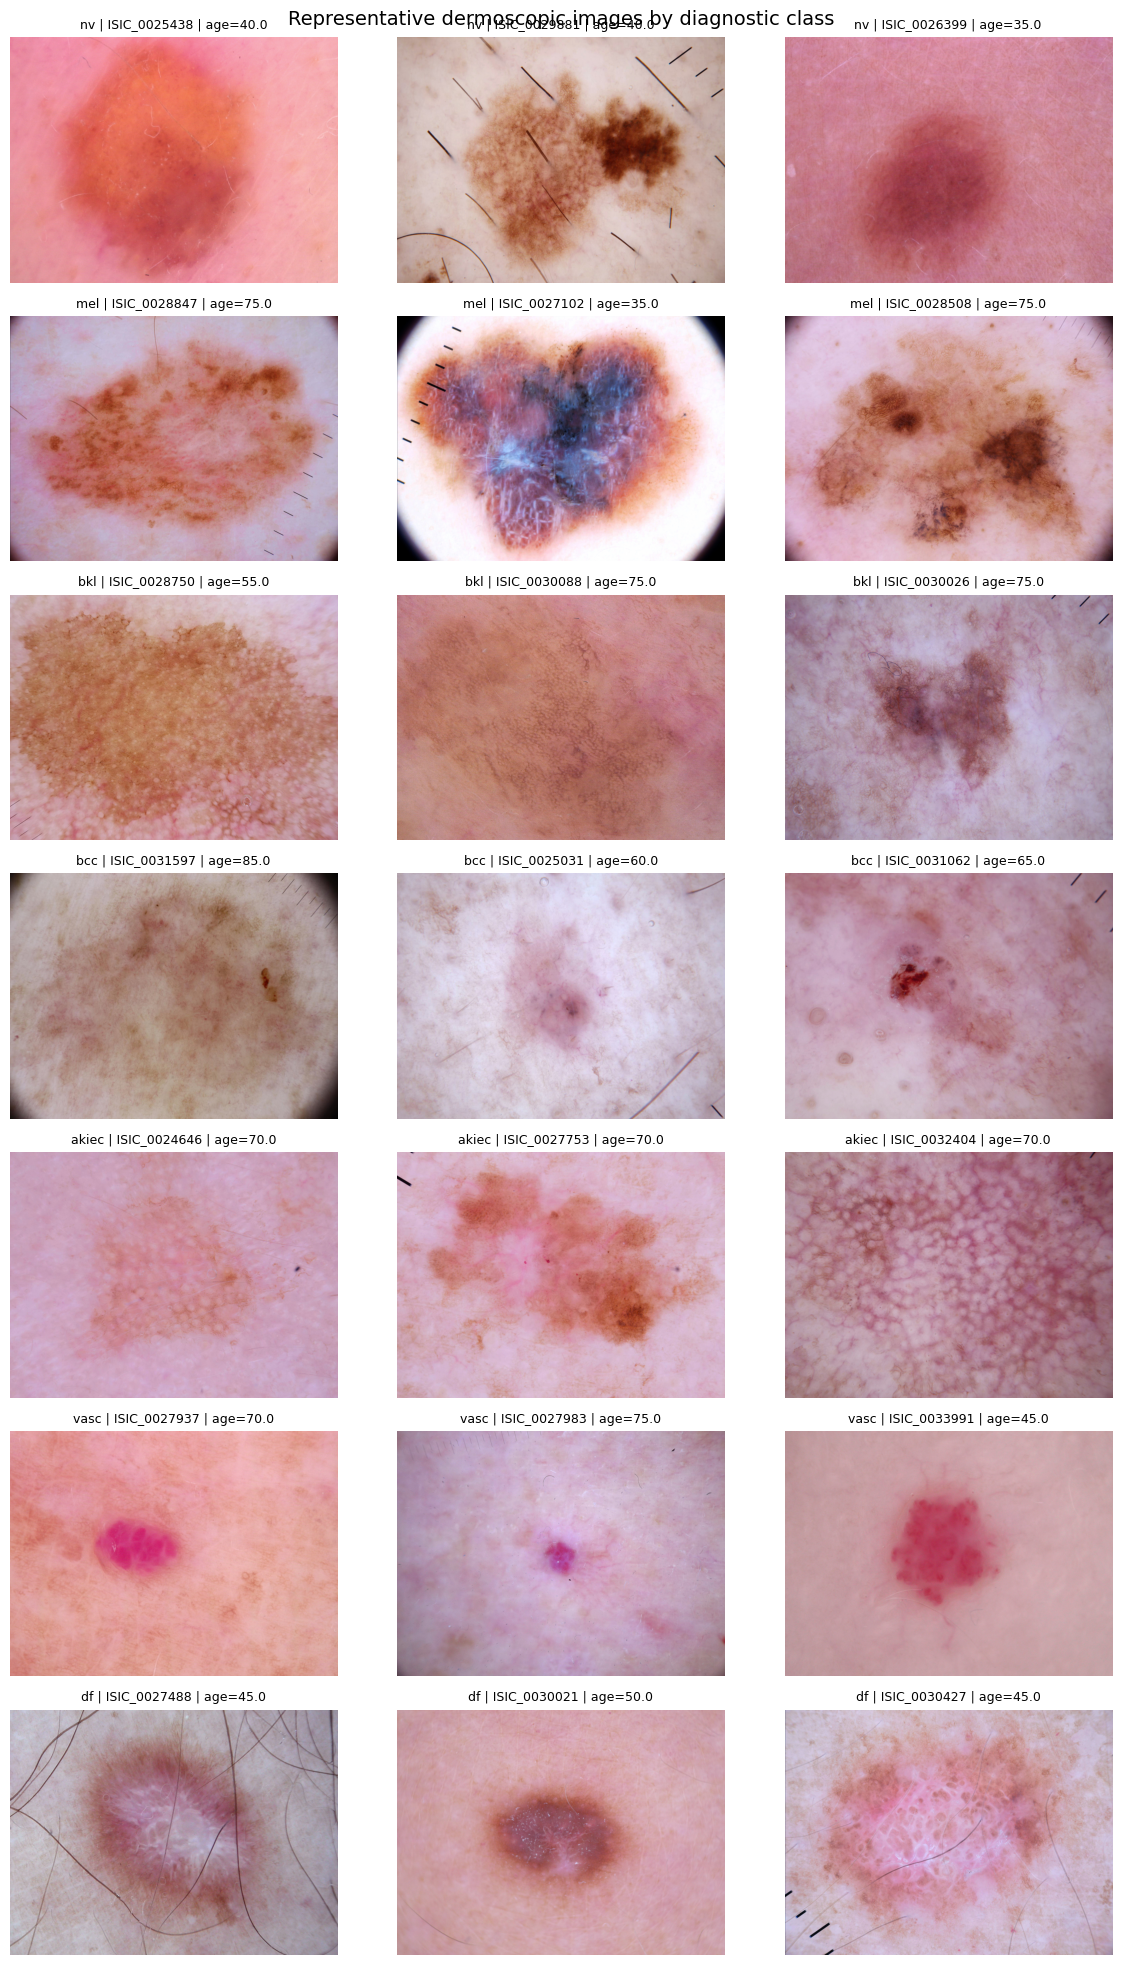

In [10]:
rows = []
for dx in DX_ORDER:
    choices = df[df['dx'] == dx]
    rows.append(choices.sample(n=min(3, len(choices)), random_state=SEED))
sample_df = pd.concat(rows, ignore_index=True)

fig, axes = plt.subplots(len(DX_ORDER), 3, figsize=(12, 20))
for r, dx in enumerate(DX_ORDER):
    class_images = sample_df[sample_df['dx'] == dx].reset_index(drop=True)
    for c in range(3):
        ax = axes[r, c]
        if c < len(class_images):
            rec = class_images.iloc[c]
            with Image.open(rec['image_path']) as img:
                ax.imshow(ImageOps.exif_transpose(img).convert('RGB'))
            ax.set_title(f"{dx} | {rec['image_id']} | age={rec['age']}", fontsize=9)
        ax.axis('off')
    axes[r, 0].set_ylabel(dx.upper(), rotation=90, fontsize=12)
fig.suptitle('Representative dermoscopic images by diagnostic class', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT / '08_samples_by_class.png', dpi=160, bbox_inches='tight')
plt.show()

## 11. Image quality audit: dimensions, channels, loading errors and pixel summaries

**Quick mode** checks 600 randomly chosen photographs. Switch `RUN_FULL_IMAGE_AUDIT=True` in Section 1 and rerun for a full-image audit (recommended before final modelling). Low/high brightness is an *inspection flag*, not automatically a reason to drop medical images.

Auditing images:   0%|          | 0/10015 [00:00<?, ?it/s]

Coverage: 10015 / 10015 images
Loading/corruption errors in audited images: 0

Most frequent image dimensions:


width  height
600    450       10015
dtype: int64


Color modes:


mode
RGB    10015
Name: count, dtype: int64


Pixel summary:


,mean_rgb,std_rgb,mean_r,mean_g,mean_b
count,10015.000000,10015.000000,10015.000000,10015.000000,10015.000000
mean,159.849875,40.500306,194.732961,139.296907,145.519758
std,19.179612,11.592660,25.056212,21.862100,24.242315
min,63.639755,10.161263,63.069660,52.042645,55.494141
25%,146.824486,31.242968,176.651695,124.921551,129.585938
50%,159.825851,41.512856,196.994461,139.194992,145.343430
75%,172.710938,49.183844,213.819016,153.542809,161.272461
max,231.806641,89.376251,254.093430,224.070969,238.222977


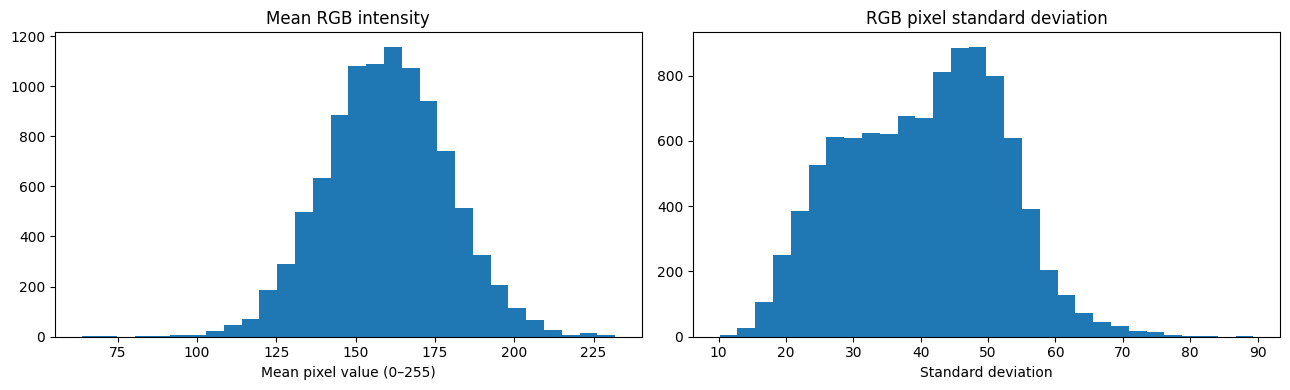

In [11]:
if RUN_FULL_IMAGE_AUDIT:
    audit_df = df.copy()
else:
    audit_df = df.sample(n=min(SAMPLED_IMAGE_COUNT, len(df)), random_state=SEED).copy()

records = []
for r in tqdm(audit_df[['image_id', 'dx', 'image_path']].itertuples(index=False), total=len(audit_df), desc='Auditing images'):
    rec = {'image_id': r.image_id, 'dx': r.dx, 'image_path': r.image_path, 'status': 'ok'}
    try:
        with Image.open(r.image_path) as im:
            rec['width'], rec['height'] = im.size
            rec['mode'] = im.mode
            rgb = ImageOps.exif_transpose(im).convert('RGB')
            rgb.thumbnail((64, 64))
            arr = np.asarray(rgb, dtype=np.float32)
            rec['mean_rgb'] = float(arr.mean())
            rec['std_rgb'] = float(arr.std())
            rec['mean_r'] = float(arr[:, :, 0].mean())
            rec['mean_g'] = float(arr[:, :, 1].mean())
            rec['mean_b'] = float(arr[:, :, 2].mean())
            im.verify()
    except Exception as exc:
        rec['status'] = f'{type(exc).__name__}: {exc}'
    records.append(rec)

image_audit = pd.DataFrame(records)
image_audit.to_csv(OUTPUT / 'image_quality_audit.csv', index=False)
print('Coverage:', len(image_audit), '/', len(df), 'images')
print('Loading/corruption errors in audited images:', int((image_audit['status'] != 'ok').sum()))
print('\nMost frequent image dimensions:')
display(image_audit.groupby(['width', 'height'], dropna=False).size().sort_values(ascending=False).head(15))
print('\nColor modes:')
display(image_audit['mode'].value_counts(dropna=False))
print('\nPixel summary:')
display(image_audit[['mean_rgb', 'std_rgb', 'mean_r', 'mean_g', 'mean_b']].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(image_audit['mean_rgb'].dropna().to_numpy(), bins=30)
axes[0].set(title='Mean RGB intensity', xlabel='Mean pixel value (0–255)')
axes[1].hist(image_audit['std_rgb'].dropna().to_numpy(), bins=30)
axes[1].set(title='RGB pixel standard deviation', xlabel='Standard deviation')
plt.tight_layout()
fig.savefig(OUTPUT / '09_image_pixel_statistics.png', dpi=180)
plt.show()

failed = image_audit[image_audit['status'] != 'ok']
if not failed.empty:
    display(failed[['image_id', 'status']].head(20))

## 12. Inspect extreme image brightness as potential quality-control candidates

This is *qualitative review*, not automated deletion. Dark image areas and black image borders can be legitimate dermoscopic characteristics.

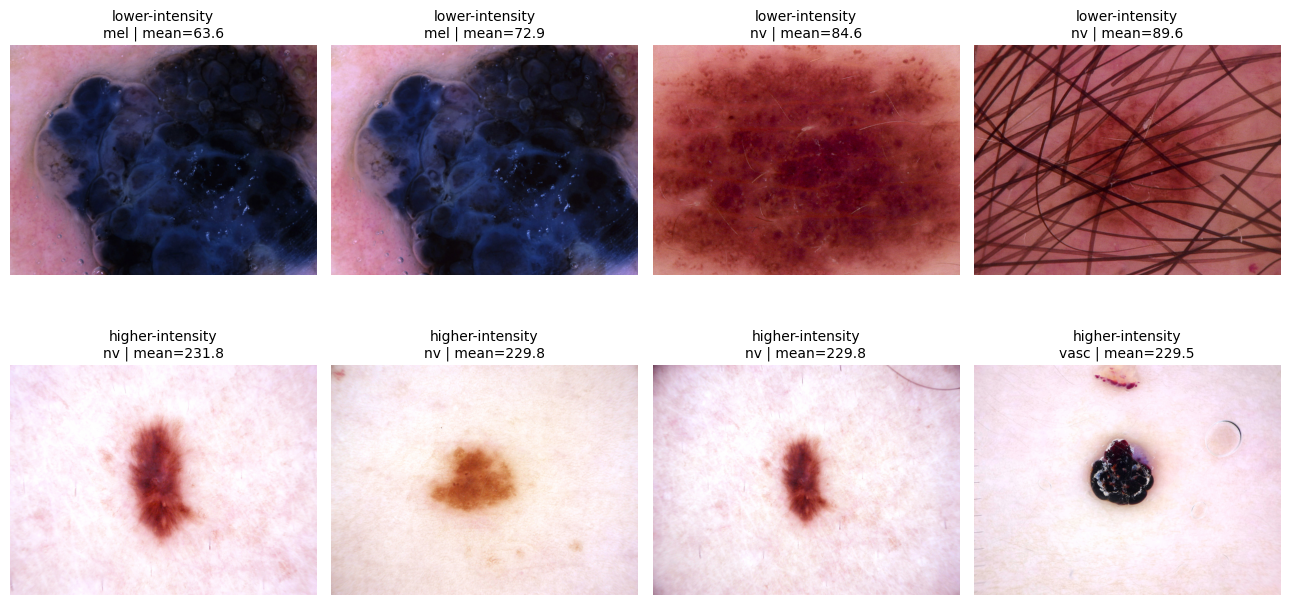

In [12]:
valid_quality = image_audit[image_audit['status'] == 'ok'].dropna(subset=['mean_rgb'])
if len(valid_quality):
    dark = valid_quality.nsmallest(4, 'mean_rgb')
    bright = valid_quality.nlargest(4, 'mean_rgb')
    to_display = pd.concat([dark.assign(flag='lower-intensity'), bright.assign(flag='higher-intensity')])
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, rec in zip(axes.flat, to_display.itertuples(index=False)):
        with Image.open(rec.image_path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f'{rec.flag}\n{rec.dx} | mean={rec.mean_rgb:.1f}', fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    fig.savefig(OUTPUT / '10_brightness_candidates.png', dpi=170)
    plt.show()

## 13. Optional exact content-hash duplicate audit (recommended)

Repeated images of the *same lesion* are expected. Exact hashes tell us whether any image files contain identical bytes, and whether identical image content crosses different `lesion_id` values. A hash check does not catch visually similar but re-encoded/cropped duplicates. **No images are deleted.**

In [13]:
image_hashes = None
if RUN_EXACT_HASH_AUDIT:
    sha_rows = []
    for row in tqdm(df[['image_id', 'lesion_id', 'image_path']].itertuples(index=False), total=len(df), desc='SHA256 audit'):
        digest = hashlib.sha256()
        with open(row.image_path, 'rb') as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b''):
                digest.update(chunk)
        sha_rows.append({'image_id': row.image_id, 'lesion_id': row.lesion_id, 'sha256': digest.hexdigest()})
    image_hashes = pd.DataFrame(sha_rows)
    dup_hash = image_hashes[image_hashes.duplicated('sha256', keep=False)].sort_values('sha256')
    cross_group = image_hashes.groupby('sha256')['lesion_id'].nunique()
    print('Images with at least one byte-identical duplicate:', len(dup_hash))
    print('Duplicate-content hashes spanning DIFFERENT lesion IDs:', int((cross_group > 1).sum()))
    dup_hash.to_csv(OUTPUT / 'exact_duplicate_images.csv', index=False)
    image_hashes.to_csv(OUTPUT / 'image_sha256.csv', index=False)
    if (cross_group > 1).any():
        print('WARNING: identical bytes occur under different lesion IDs; resolve grouping BEFORE split!')
        display(dup_hash.head(30))
else:
    print('Hash audit SKIPPED. Set RUN_EXACT_HASH_AUDIT=True in Section 1 to enable it.')

SHA256 audit:   0%|          | 0/10015 [00:00<?, ?it/s]

Images with at least one byte-identical duplicate: 4
Duplicate-content hashes spanning DIFFERENT lesion IDs: 0


## 14. Construct stratified, **lesion-disjoint** train/validation/test splits

Use `StratifiedGroupKFold` with `lesion_id` as the grouping key. Out of 7 folds, allocate 5 to training, 1 to validation, and 1 to test (approximately **71% / 14% / 14%**, with actual ratios varying because lesions have multiple photos). This stratifies *approximately* by diagnosis while keeping repeated photographs together. **Do not augment any images before splitting.**

,images,lesions,fraction_pct
split,,,
test,1458,1068,14.56
train,7116,5335,71.05
validation,1441,1067,14.39


split,test,train,validation,total
dx,,,,
nv,935,4796,974,6705
mel,185,782,146,1113
bkl,159,772,168,1099
bcc,67,358,89,514
akiec,63,230,34,327
vasc,32,89,21,142
df,17,89,9,115


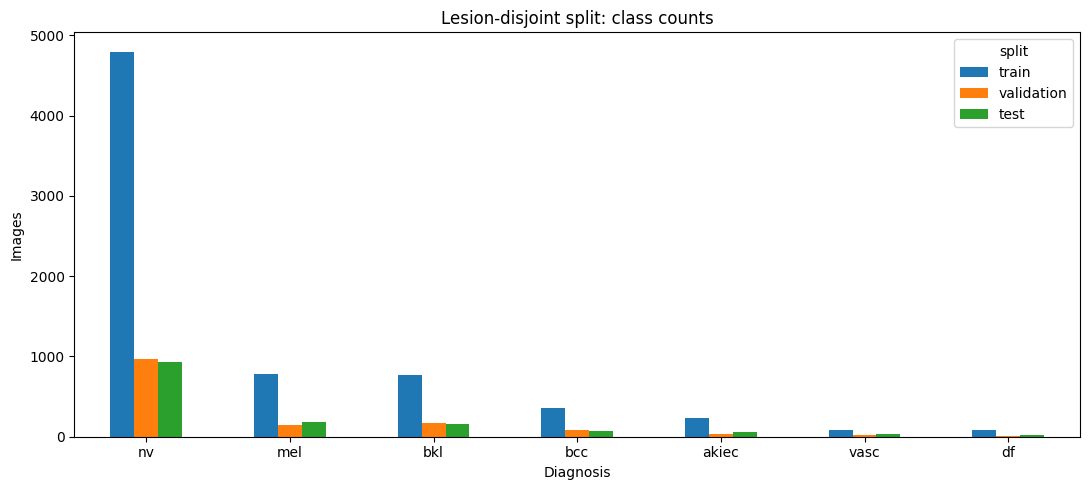

PASS: every class appears in all three subsets.
PASS: zero lesion-ID overlap among train/validation/test.


In [14]:
if RUN_EXACT_HASH_AUDIT and image_hashes is not None:
    cross_group = image_hashes.groupby('sha256')['lesion_id'].nunique()
    assert not (cross_group > 1).any(), 'Identical images cross lesion IDs; merge groups or resolve before splitting.'

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
fold_numbers = np.full(len(df), -1, dtype=np.int32)
for f_id, (_, holdout_idx) in enumerate(sgkf.split(df, y=df['dx'], groups=df['lesion_id'])):
    fold_numbers[holdout_idx] = f_id
assert (fold_numbers >= 0).all(), 'Not all rows were assigned to folds.'
df['fold'] = fold_numbers
df['split'] = np.where(df['fold'] == 0, 'validation', np.where(df['fold'] == 1, 'test', 'train'))

# The same lesion must never occur in two different subsets.
sets = {name: set(df.loc[df['split'] == name, 'lesion_id']) for name in ['train', 'validation', 'test']}
assert sets['train'].isdisjoint(sets['validation'])
assert sets['train'].isdisjoint(sets['test'])
assert sets['validation'].isdisjoint(sets['test'])
assert df.groupby('lesion_id')['split'].nunique().max() == 1

split_stats = df.groupby('split').agg(images=('image_id', 'count'), lesions=('lesion_id', 'nunique'))
split_stats['fraction_pct'] = (100 * split_stats['images'] / len(df)).round(2)
display(split_stats)
split_stats.to_csv(OUTPUT / 'split_overview.csv')

split_by_class = pd.crosstab(df['dx'], df['split']).reindex(DX_ORDER, fill_value=0)
split_by_class['total'] = split_by_class.sum(axis=1)
display(split_by_class)
split_by_class.to_csv(OUTPUT / 'split_class_distribution.csv')

fig, ax = plt.subplots(figsize=(11, 5))
split_by_class[['train', 'validation', 'test']].plot(kind='bar', ax=ax)
ax.set(title='Lesion-disjoint split: class counts', ylabel='Images', xlabel='Diagnosis')
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(OUTPUT / '11_split_class_counts.png', dpi=180)
plt.show()

if (split_by_class[['train', 'validation', 'test']] == 0).any().any():
    print('WARNING: at least one class is absent in a subset; adjust the fold seed and recheck.')
else:
    print('PASS: every class appears in all three subsets.')
print('PASS: zero lesion-ID overlap among train/validation/test.')

## 15. Check class proportions **within** each split, and investigate remaining biases

Even lesion-level stratification cannot guarantee perfect balance. Examine differences across train, validation and test. Use the **original class prevalence** in validation and test; class weighting and augmentation belong in the training pipeline only.

split,train,validation,test
dx,,,
nv,67.40,67.59,64.13
mel,10.99,10.13,12.69
bkl,10.85,11.66,10.91
bcc,5.03,6.18,4.60
akiec,3.23,2.36,4.32
vasc,1.25,1.46,2.19
df,1.25,0.62,1.17


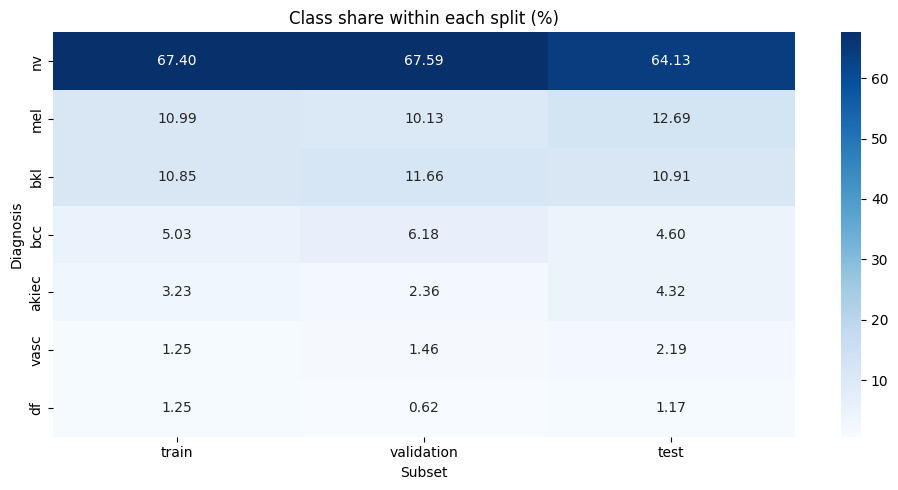

Rows in manifest: 10015
Unique image IDs: 10015
Unique lesion IDs: 7470
Split labels: ['test', 'train', 'validation']
Patient-disjoint? NOT VERIFIED (no patient ID in HAM10000 metadata).


In [15]:
proportions = pd.crosstab(df['dx'], df['split'], normalize='columns').reindex(DX_ORDER, fill_value=0) * 100
proportions = proportions[['train', 'validation', 'test']].round(2)
display(proportions)
proportions.to_csv(OUTPUT / 'split_class_percentage.csv')

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(proportions, annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set(title='Class share within each split (%)', ylabel='Diagnosis', xlabel='Subset')
plt.tight_layout()
fig.savefig(OUTPUT / '12_split_class_proportions.png', dpi=180)
plt.show()

# Confirm that every observation belongs to exactly one group and split.
print('Rows in manifest:', len(df))
print('Unique image IDs:', df['image_id'].nunique())
print('Unique lesion IDs:', df['lesion_id'].nunique())
print('Split labels:', sorted(df['split'].unique()))
print('Patient-disjoint? NOT VERIFIED (no patient ID in HAM10000 metadata).')

## 16. Export reproducible manifests, figures and machine-readable report

The `image_relpath` column makes it possible to reconstruct local paths if moving the dataset; `image_path` is the direct Kaggle path. The notebook does **not** modify the read-only original dataset.

In [16]:
ordered_cols = ['image_id', 'lesion_id', 'dx', 'dx_type', 'age', 'sex', 'localization',
                'image_relpath', 'image_path', 'fold', 'split']
for optional in ['age_num']:
    if optional in df.columns:
        ordered_cols.append(optional)
manifest = df[ordered_cols].copy()
manifest.to_csv(OUTPUT / 'ham10000_master_manifest.csv', index=False)
for subset in ['train', 'validation', 'test']:
    manifest[manifest['split'] == subset].to_csv(OUTPUT / f'{subset}_manifest.csv', index=False)

summary = {
    'source_dataset': 'kmader/skin-cancer-mnist-ham10000',
    'original_reference': 'Tschandl et al., HAM10000, 2018, doi:10.7910/DVN/DBW86T',
    'random_seed': SEED,
    'image_count_in_metadata': int(len(df)),
    'unique_image_ids': int(df['image_id'].nunique()),
    'unique_lesion_ids': int(df['lesion_id'].nunique()),
    'images_with_missing_files': int(df['image_path'].isna().sum()),
    'duplicate_image_ids': int(df['image_id'].duplicated().sum()),
    'lesions_with_multiple_images': int((images_per_lesion > 1).sum()),
    'lesions_with_conflicting_dx': int((labels_per_lesion > 1).sum()),
    'class_counts': {code: int(class_counts[code]) for code in DX_ORDER},
    'missing_values': {c: int(df[c].isna().sum()) for c in required},
    'diagnosis_confirmation_counts': {str(k): int(v) for k, v in df['dx_type'].value_counts(dropna=False).items()},
    'split_counts': {name: int((df['split'] == name).sum()) for name in ['train', 'validation', 'test']},
    'split_group_method': 'StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42), fold 0 val, fold 1 test',
    'split_lesion_overlap': 0,
    'patient_disjoint_guaranteed': False,
    'full_image_audit': RUN_FULL_IMAGE_AUDIT,
    'images_quality_audited': int(len(image_audit)),
    'quality_audit_failures': int((image_audit['status'] != 'ok').sum()),
    'exact_hash_audit_completed': RUN_EXACT_HASH_AUDIT,
    'python_version': sys.version.split()[0],
    'pandas_version': pd.__version__,
    'numpy_version': np.__version__,
    'sklearn_version': sklearn.__version__,
}
with open(OUTPUT / 'audit_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

files = sorted(p for p in OUTPUT.iterdir() if p.is_file())
print('Audit completed: created', len(files), 'files.')
for f in files:
    print(f.name, f'({f.stat().st_size/1024:.0f} KiB)')
print('\nSummary for report:')
pprint(summary)

Audit completed: created 33 files.
01_class_distribution.png (59 KiB)
02_images_per_lesion.png (41 KiB)
03_confirmation_method_heatmap.png (79 KiB)
04_age_distribution.png (37 KiB)
05_age_by_class.png (47 KiB)
06_sex_by_class.png (74 KiB)
07_body_site_by_class.png (101 KiB)
08_samples_by_class.png (6669 KiB)
09_image_pixel_statistics.png (57 KiB)
10_brightness_candidates.png (2659 KiB)
11_split_class_counts.png (46 KiB)
12_split_class_proportions.png (73 KiB)
audit_summary.json (1 KiB)
class_distribution.csv (0 KiB)
diagnosis_confirmation_by_class.csv (0 KiB)
exact_duplicate_images.csv (0 KiB)
file_inventory.csv (996 KiB)
ham10000_master_manifest.csv (2022 KiB)
image_copy_inventory_fast.csv (1682 KiB)
image_quality_audit.csv (2105 KiB)
image_sha256.csv (880 KiB)
images_per_lesion.csv (102 KiB)
localization_by_class.csv (0 KiB)
metadata_missingness.csv (0 KiB)
missing_images.csv (0 KiB)
orphan_images.csv (0 KiB)
sex_by_class.csv (0 KiB)
split_class_distribution.csv (0 KiB)
split_class_p

## 17. Interpretation worksheet: turn audit results into research decisions

Complete this **after running** all preceding sections. Do not invent outcomes.

| Question | Where to find the evidence | Proposed action if indicated |
|---|---|---|
| Are there 10,015 images in metadata and on disk? | Section 5, `missing_images.csv` | Repair missing links or document exclusions |
| How severe is the class imbalance? | Section 6, `class_distribution.csv` | Test weighted cross-entropy or focal loss (train only) |
| How many lesions have repeat photographs? | Section 7 | Always split using `lesion_id`; never only image IDs |
| Are diagnostic confirmation methods uneven by class? | Section 8, heatmap | Discuss possible label-verification bias |
| How much age/sex/site data is absent or unknown? | Sections 4, 9 | Decide whether to exclude or impute metadata; do not impute from test distribution |
| What dimensions and color modes exist? | Section 11 | Choose input size, RGB conversion and model-specific normalization |
| Are images unreadable or visually suspicious? | Sections 10–12 | Investigate individually; don't blindly discard |
| Are any byte-identical files mapped to different lesions? | Section 13, if enabled | Resolve group leakage before accepting splits |
| Do all three subsets contain all seven diagnoses? | Sections 14–15 | Adjust splitting strategy if a rare class is absent |

### Recommended next stage (separate notebook)
1. Train a **CNN-only EfficientNet-B0 baseline** with the saved group-disjoint manifests.
2. Apply transforms to training data only (resize, gentle rotations/flips/color modifications); deterministic preprocessing for validation/test.
3. Choose model using validation macro-F1 and balanced accuracy; leave the test set untouched until final evaluation.
4. Compare CNN alone with class-weighted CNN, calibrated CNN and CNN + Mamdani fuzzy inference layer.
5. Measure balanced accuracy, macro-F1, per-class recall (especially `mel`), ROC-AUC if appropriate, confusion matrices, reliability/calibration and selective-review coverage/error.
6. Use Grad-CAM only after model training to visualize influential regions, **not** to claim clinical causation.

### Safeguards specific to this project
- `dx_type`, `image_id`, `lesion_id` and `fold` **must not be predictive model features**.
- The `lesion_id` check is **lesion-disjoint**, not guaranteed patient-disjoint.
- Train-only augmentation, class weights and imputation; don't contaminate validation/test.
- Avoid treating high softmax confidence as calibrated medical certainty.
- Skin tone is not systematically annotated, so do not assert fairness across skin-tone groups without a suitable additional dataset.
- Avoid comparisons of accuracy to other papers unless their splits, validation scheme and test sets are aligned.
- No direct clinical deployment or cancer diagnosis claims: this is an educational research prototype.

## 18. Prepare the SEVEN-CLASS manifests (replaces the previous binary-only cells)

**Goal:** retain all **10,015 images** and **all seven diagnoses** from the verified `ham10000_master_manifest.csv`. Existing lesion-disjoint assignments from Section 14 remain unchanged. The model will receive a **seven-output classification head**.

Label order is explicit and persisted for reproducibility:

| Numeric label | Diagnosis code | Meaning |
|---:|---|---|
| 0 | `nv` | Melanocytic nevi |
| 1 | `mel` | Melanoma |
| 2 | `bkl` | Benign keratosis-like lesions |
| 3 | `bcc` | Basal cell carcinoma |
| 4 | `akiec` | Actinic keratoses / intraepithelial carcinoma |
| 5 | `vasc` | Vascular lesions |
| 6 | `df` | Dermatofibroma |

**Note:** These are seven *diagnoses*, not seven cancers. `dx_type` records how the diagnosis was established and is **not** an input to the neural network. `lesion_id` is for grouping only. No training or label reclassification is performed in this section.


In [17]:
from pathlib import Path
import json
import pandas as pd

AUDIT_DIR = Path('/kaggle/working/ham10000_audit')
SEVEN_DIR = Path('/kaggle/working/ham10000_7class')
SEVEN_DIR.mkdir(parents=True, exist_ok=True)

# Read the original seven-class audit manifest exported in Section 16.
source = AUDIT_DIR / 'ham10000_master_manifest.csv'
if not source.is_file():
    raise FileNotFoundError('Run Sections 1 through 16 to create the verified full manifest first.')
full = pd.read_csv(source)

CLASS_CODES = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']
CLASS_TO_IDX = {code: idx for idx, code in enumerate(CLASS_CODES)}
IDX_TO_CLASS = {str(idx): code for code, idx in CLASS_TO_IDX.items()}

required_cols = {'image_id', 'lesion_id', 'dx', 'image_path', 'split'}
assert required_cols.issubset(full.columns)
assert len(full) == 10015, 'Expected all 10,015 original HAM10000 images.'
assert full['image_id'].is_unique
assert full['lesion_id'].notna().all()
assert set(full['dx']) == set(CLASS_CODES)
assert set(full['split']) == {'train', 'validation', 'test'}
assert full['image_path'].notna().all()

# Keep all seven labels. DO NOT drop the five categories as in the former binary subset.
full['label'] = full['dx'].map(CLASS_TO_IDX).astype('int64')

# Reconfirm no lesion ID is shared across datasets.
assert full.groupby('lesion_id')['split'].nunique().max() == 1, 'LEAKAGE: lesion in multiple partitions.'

class_counts = pd.crosstab(full['dx'], full['split']).reindex(
    index=CLASS_CODES, columns=['train','validation','test'], fill_value=0
)
assert class_counts.gt(0).all().all(), 'Missing a diagnosis in a partition.'
assert class_counts.to_numpy().sum() == 10015

# Preserve source image paths + split assignments; numeric labels are added.
full.to_csv(SEVEN_DIR / 'seven_class_master_manifest.csv', index=False)
for split_name in ['train', 'validation', 'test']:
    full.loc[full['split'] == split_name].to_csv(
        SEVEN_DIR / f'{split_name}_7class.csv', index=False
    )
class_counts.to_csv(SEVEN_DIR / 'seven_class_split_counts.csv')
with (SEVEN_DIR / 'class_mapping.json').open('w') as f:
    json.dump({'class_codes': CLASS_CODES, 'class_to_index': CLASS_TO_IDX,
               'index_to_class': IDX_TO_CLASS}, f, indent=2)

print('Seven-class split counts:')
display(class_counts)
print('Train / validation / test totals:', class_counts.sum(axis=0).to_dict())
print('All seven classes retained:', len(CLASS_CODES))
print('Images retained:', len(full))
print('Unique lesions:', full['lesion_id'].nunique())
print('Lesion overlap across splits: 0')
print('Saved to:', SEVEN_DIR)
print('PASS: seven-class manifests and class mapping ready for EfficientNet-B0.')

Seven-class split counts:


split,train,validation,test
dx,,,
nv,4796,974,935
mel,782,146,185
bkl,772,168,159
bcc,358,89,67
akiec,230,34,63
vasc,89,21,32
df,89,9,17


Train / validation / test totals: {'train': 7116, 'validation': 1441, 'test': 1458}
All seven classes retained: 7
Images retained: 10015
Unique lesions: 7470
Lesion overlap across splits: 0
Saved to: /kaggle/working/ham10000_7class
PASS: seven-class manifests and class mapping ready for EfficientNet-B0.


## 19. Before model training — data-centric quality gates and planned evaluation

### Remaining quality checks

- [ ] Set `RUN_FULL_IMAGE_AUDIT = True` and `RUN_EXACT_HASH_AUDIT = True` in Section 1, then rerun the **complete audit**; resolve cross-`lesion_id` exact duplicates before accepting splits.
- [ ] Confirm the saved version includes `ham10000_audit/` **and** `ham10000_7class/` output folders.
- [ ] Preserve the **same lesion-disjoint split** across all model variants. Never perform augmentation or oversampling before splitting.
- [ ] Apply image preprocessing to all splits, but augmentation / class balancing **only to training**.
- [ ] Use `class_mapping.json` unchanged during training, validation, test evaluation and reporting.

### Next notebook — pretrained EfficientNet-B0 baseline

Use ImageNet-pretrained EfficientNet-B0 with a seven-output classification head. Compare unweighted and class-weighted cross-entropy; optionally test careful minority-class augmentation. The smallest classes (e.g., `df`, `vasc`) have relatively few independent lesions. Do not assume a single high accuracy score is meaningful.

**Classification evaluation (ISIC 2018 Task 3 aligned):** balanced accuracy, macro-F1, seven-class confusion matrix, per-class recall and precision (especially melanoma), per-class one-vs-rest ROC-AUC / PR-AUC where supported, and calibration. Report confidence intervals or sample counts for tiny classes.

**Mamdani fuzzy decision layer:** evaluate uncertain-prediction/quality review decisions **separately** from diagnosis accuracy. Compare fuzzy decisions with simpler thresholds using the same held-out cases and review budget. Fuzzy postprocessing does not necessarily change CNN classification accuracy.

**Research scope:** this is a seven-diagnosis, dermoscopic-image classification research prototype, not a certified cancer diagnostic or clinical triage system.
